<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/05_accretion_disk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import sys

repo_path = "/content/Blackhole_simulator_rayTracing"

if not os.path.exists(repo_path):
    %cd /content
    !git clone https://github.com/AnshG-19/Blackhole_simulator_rayTracing.git

os.chdir(repo_path)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

print("Repository connected:", os.getcwd())

/content
Cloning into 'Blackhole_simulator_rayTracing'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 76 (delta 19), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 1.43 MiB | 14.08 MiB/s, done.
Resolving deltas: 100% (19/19), done.
Repository connected: /content/Blackhole_simulator_rayTracing


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Use geometric units: G = c = 1
M = 1.0

# Schwarzschild black hole
event_horizon = 2 * M
photon_sphere = 3 * M
isco_radius = 6 * M  # Innermost stable circular orbit

# Accretion disk boundaries
disk_inner = isco_radius
disk_outer = 15 * M

print("Accretion Disk — Geometry")
print("-------------------------")
print(f"Event horizon radius: {event_horizon:.1f} M")
print(f"Photon sphere radius: {photon_sphere:.1f} M")
print(f"ISCO radius: {isco_radius:.1f} M")
print(f"Disk outer radius: {disk_outer:.1f} M")

Accretion Disk — Geometry
-------------------------
Event horizon radius: 2.0 M
Photon sphere radius: 3.0 M
ISCO radius: 6.0 M
Disk outer radius: 15.0 M


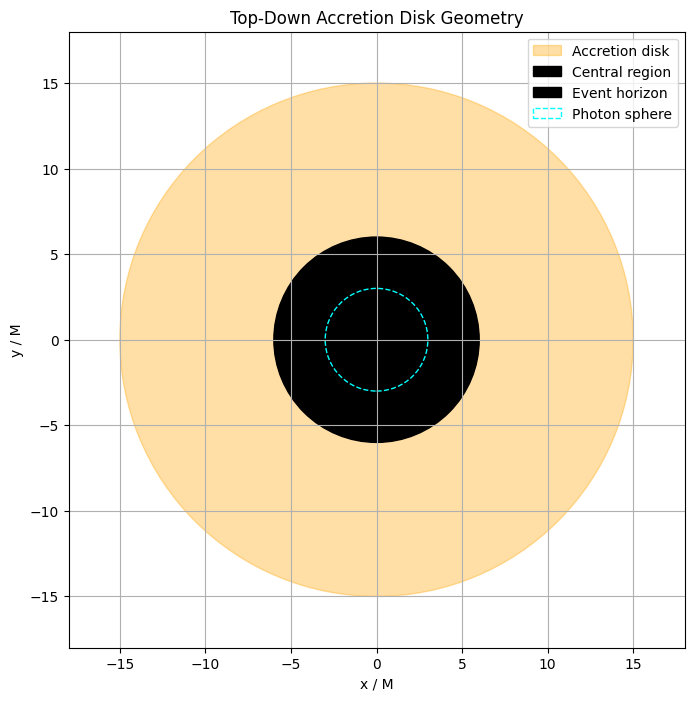

In [3]:
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(8, 8))

# Draw the accretion disk as a ring
disk = Circle(
    (0, 0),
    disk_outer,
    color="orange",
    alpha=0.35,
    label="Accretion disk",
)
ax.add_patch(disk)

inner_edge = Circle(
    (0, 0),
    disk_inner,
    color="black",
    label="Central region",
)
ax.add_patch(inner_edge)

# Draw the event horizon and photon sphere
ax.add_patch(
    Circle((0, 0), event_horizon, color="black", label="Event horizon")
)
ax.add_patch(
    Circle(
        (0, 0),
        photon_sphere,
        fill=False,
        linestyle="--",
        color="cyan",
        label="Photon sphere",
    )
)

ax.set_xlim(-18, 18)
ax.set_ylim(-18, 18)
ax.set_aspect("equal")
ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Top-Down Accretion Disk Geometry")
ax.legend(loc="upper right")
ax.grid(True)

plt.show()

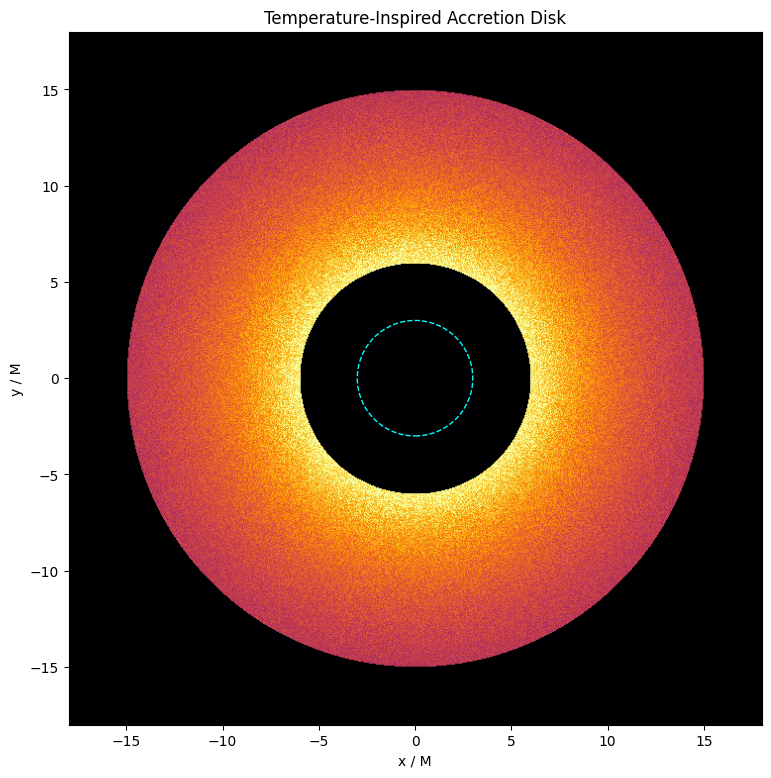

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Create a 2D grid around the black hole
grid_size = 700
extent = 18 * M

x = np.linspace(-extent, extent, grid_size)
y = np.linspace(-extent, extent, grid_size)
X, Y = np.meshgrid(x, y)

# Distance from the black hole center
R = np.sqrt(X**2 + Y**2)

# Avoid division by zero
R_safe = np.maximum(R, disk_inner)

# Disk region
disk_mask = (R >= disk_inner) & (R <= disk_outer)

# Approximate temperature profile: hotter toward the inner edge
temperature = (R_safe / disk_inner) ** (-0.75)

# Convert temperature profile into visible brightness
brightness = np.zeros_like(R)
brightness[disk_mask] = temperature[disk_mask]

# Add subtle variations to give the disk a textured appearance
rng = np.random.default_rng(42)
texture = rng.uniform(0.85, 1.15, size=R.shape)
brightness[disk_mask] *= texture[disk_mask]

# Plot
fig, ax = plt.subplots(figsize=(9, 9))

ax.imshow(
    brightness,
    extent=[-extent, extent, -extent, extent],
    origin="lower",
    cmap="inferno",
    vmin=0,
    vmax=1,
)

ax.add_patch(plt.Circle((0, 0), event_horizon, color="black"))
ax.add_patch(
    plt.Circle(
        (0, 0),
        photon_sphere,
        fill=False,
        linestyle="--",
        color="cyan",
        linewidth=1,
    )
)

ax.set_xlim(-18, 18)
ax.set_ylim(-18, 18)
ax.set_aspect("equal")
ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Temperature-Inspired Accretion Disk")
plt.show()

Orbital Motion
----------------------------------------
Radius (M)     Angular velocity    
6.0            0.06804             
8.0            0.04419             
10.0           0.03162             
12.0           0.02406             
15.0           0.01721             


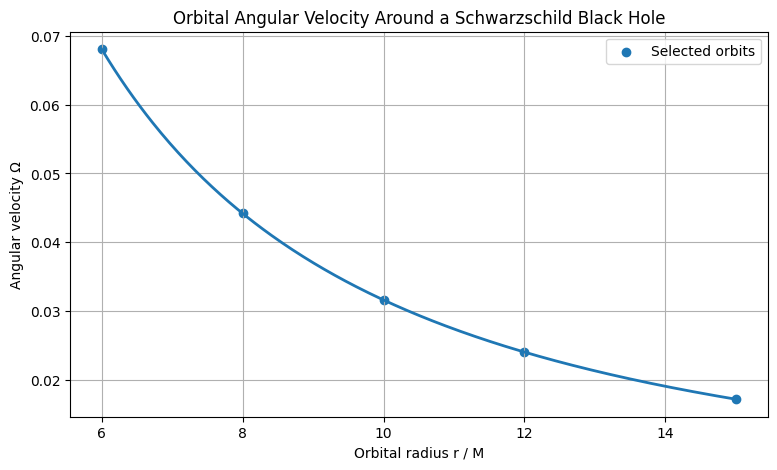

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Choose several orbital radii in the disk
radii = np.array([6.0, 8.0, 10.0, 12.0, 15.0]) * M

# Circular orbital angular velocity in geometric units
angular_velocity = np.sqrt(M / radii**3)

print("Orbital Motion")
print("-" * 40)
print(f"{'Radius (M)':<15}{'Angular velocity':<20}")

for radius, omega in zip(radii, angular_velocity):
    print(f"{radius / M:<15.1f}{omega:<20.5f}")

# Plot angular velocity against radius
radius_values = np.linspace(disk_inner, disk_outer, 300)
omega_values = np.sqrt(M / radius_values**3)

plt.figure(figsize=(9, 5))
plt.plot(radius_values / M, omega_values, linewidth=2)
plt.scatter(radii / M, angular_velocity, label="Selected orbits")
plt.xlabel("Orbital radius r / M")
plt.ylabel("Angular velocity Ω")
plt.title("Orbital Angular Velocity Around a Schwarzschild Black Hole")
plt.grid(True)
plt.legend()
plt.show()

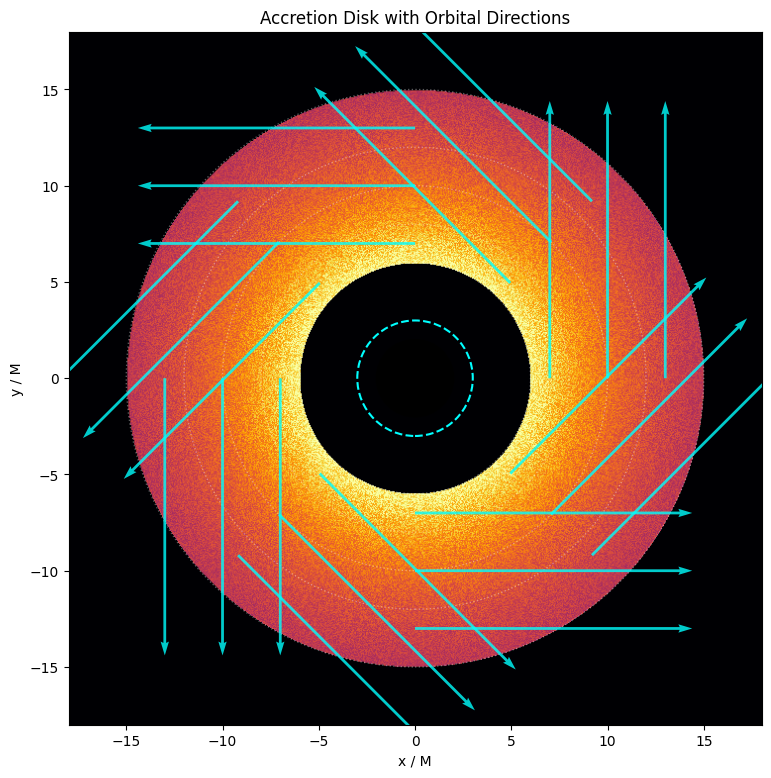

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(9, 9))

# Show the glowing disk background
ax.imshow(
    brightness,
    extent=[-extent, extent, -extent, extent],
    origin="lower",
    cmap="inferno",
    vmin=0,
    vmax=1,
)

# Draw circular orbital paths
for radius in [6, 8, 10, 12, 15]:
    ax.add_patch(
        Circle(
            (0, 0),
            radius * M,
            fill=False,
            color="white",
            alpha=0.35,
            linestyle=":",
        )
    )

# Draw tangential velocity arrows at selected positions
for radius in [7, 10, 13]:
    theta = np.linspace(0, 2 * np.pi, 9)[:-1]

    # Position on each circular orbit
    x_pos = radius * M * np.cos(theta)
    y_pos = radius * M * np.sin(theta)

    # Tangential direction for counterclockwise motion
    u = -np.sin(theta)
    v = np.cos(theta)

    ax.quiver(
        x_pos,
        y_pos,
        u,
        v,
        color="cyan",
        scale=2.5,
        width=0.004,
        alpha=0.8,
    )

# Central black hole and photon sphere
ax.add_patch(Circle((0, 0), event_horizon, color="black"))
ax.add_patch(
    Circle(
        (0, 0),
        photon_sphere,
        fill=False,
        linestyle="--",
        color="cyan",
        linewidth=1.5,
    )
)

ax.set_xlim(-18, 18)
ax.set_ylim(-18, 18)
ax.set_aspect("equal")
ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Accretion Disk with Orbital Directions")
plt.show()

## Accretion Disk Simulation — Summary

This notebook visualizes a simplified accretion disk around a non-rotating Schwarzschild black hole using geometric units, where \(G=c=1\).

### Features implemented
- Event horizon, photon sphere, and innermost stable circular orbit (ISCO).
- Disk geometry extending from \(6M\) to \(15M\).
- Radial temperature-inspired brightness profile with illustrative texture.
- Circular orbital angular velocity, \(\Omega=\sqrt{M/r^3}\).
- Tangential arrows indicating counterclockwise orbital motion.

### Physical limitations
This is an educational visualization rather than a complete relativistic accretion-disk simulation. It does not calculate relativistic radiation transfer, Doppler beaming, gravitational redshift, or hydrodynamic turbulence. The texture is illustrative.

### Main conclusion
In the simplified model, the disk is brightest toward its inner edge, while orbital angular velocity decreases with increasing radius. These features help illustrate how material behaves near a black hole.



# Black Hole Simulator — Accretion Disk

## Objectives
- Model an accretion disk around a black hole
- Create a radial brightness profile
- Visualize disk temperature using colour
- Understand the limits of a top-down model


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.patches import Circle

# print("Accretion disk simulation initialized.")

Accretion disk simulation initialized.


Define the black hole and disk

1.   Why use these values?
- The event horizon is at \(r=2M\).
- The photon sphere is at \(r=3M\).
- The disk begins at \(r=6M\), the innermost stable circular orbit for a Schwarzschild black hole in the idealized test-particle model.
- The disk ends at \(r=20M\) for this visualization.



In [ ]:
# # Geometric units: G = c = M = 1
# M = 1.0

# # Black hole geometry
# r_s = 2 * M
# r_ph = 3 * M

# # Simplified accretion disk boundaries
# r_inner = 6 * M
# r_outer = 20 * M

# print("Event horizon radius:", r_s)
# print("Photon sphere radius:", r_ph)
# print("Disk inner radius:", r_inner)
# print("Disk outer radius:", r_outer)

Event horizon radius: 2.0
Photon sphere radius: 3.0
Disk inner radius: 6.0
Disk outer radius: 20.0


Create a 2D grid
What is happening here?
1. np.linspace() generates evenly spaced coordinates.
2. np.meshgrid() combines the horizontal and vertical coordinates into a 2D grid.
3. np.sqrt(X**2 + Y**2) calculates the radial distance of every grid point from the centre.
Instead of calculating one point at a time, NumPy performs the calculations on the entire grid. This technique is called vectorization.

In [ ]:
# # Create a grid covering the disk
# resolution = 800

# x = np.linspace(-r_outer, r_outer, resolution)
# y = np.linspace(-r_outer, r_outer, resolution)

# X, Y = np.meshgrid(x, y)

# # Distance of each grid point from the black hole
# R = np.sqrt(X**2 + Y**2)

# print("Grid shape:", R.shape)
# print("Grid resolution:", resolution, "x", resolution)

Grid shape: (800, 800)
Grid resolution: 800 x 800


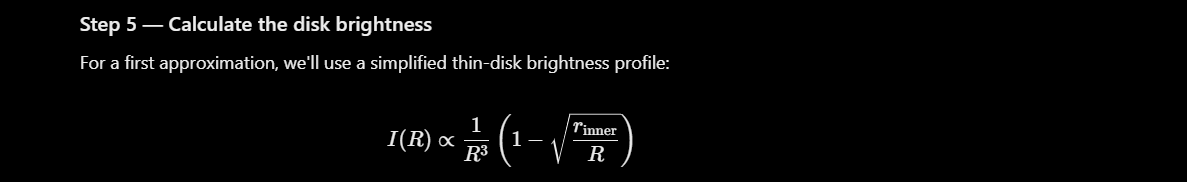

In [ ]:
# # Start with zero brightness everywhere
# brightness = np.zeros_like(R)

# # Only calculate brightness inside the disk boundaries
# disk_mask = (R >= r_inner) & (R <= r_outer)

# # Calculate the brightness profile
# brightness[disk_mask] = (
#     (r_inner / R[disk_mask])**3
#     * (1 - np.sqrt(r_inner / R[disk_mask]))
# )

# # Normalize brightness to the range 0 to 1
# brightness = brightness / brightness.max()

# print("Minimum brightness:", brightness.min())
# print("Maximum brightness:", brightness.max())

Minimum brightness: 0.0
Maximum brightness: 1.0


Render the accretion disk

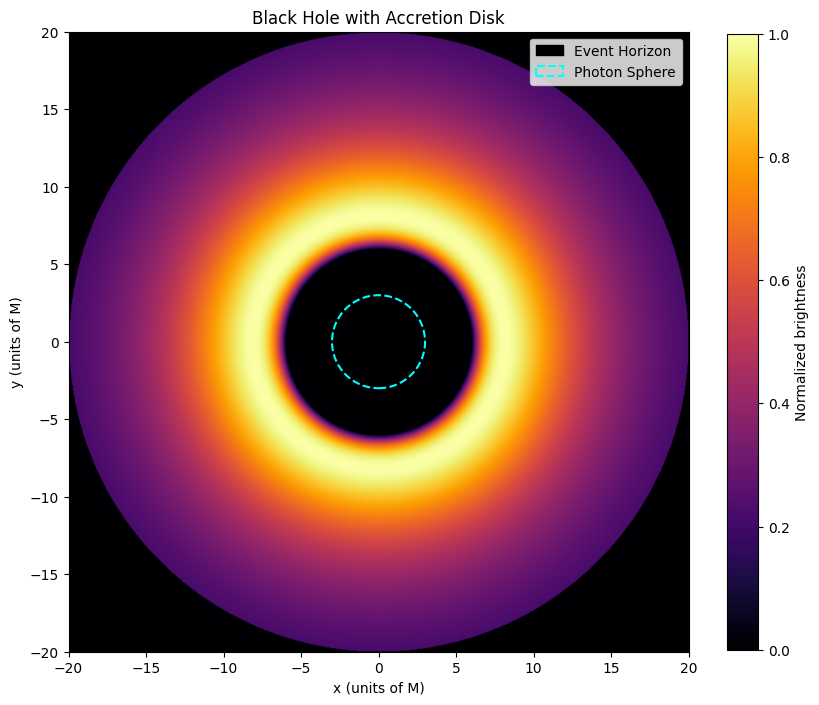

In [ ]:
# fig, ax = plt.subplots(figsize=(10, 10))

# # Display the brightness field
# image = ax.imshow(
#     brightness,
#     extent=[-r_outer, r_outer, -r_outer, r_outer],
#     origin="lower",
#     cmap="inferno",
#     interpolation="bilinear"
# )

# # Draw the event horizon
# ax.add_patch(
#     Circle(
#         (0, 0),
#         r_s,
#         color="black",
#         label="Event Horizon"
#     )
# )

# # Draw the photon sphere
# ax.add_patch(
#     Circle(
#         (0, 0),
#         r_ph,
#         fill=False,
#         linestyle="--",
#         linewidth=1.5,
#         edgecolor="cyan",
#         label="Photon Sphere"
#     )
# )

# # Configure the plot
# ax.set_aspect("equal")
# ax.set_xlim(-r_outer, r_outer)
# ax.set_ylim(-r_outer, r_outer)
# ax.set_xlabel("x (units of M)")
# ax.set_ylabel("y (units of M)")
# ax.set_title("Black Hole with Accretion Disk")
# ax.legend()

# # Add a brightness scale
# colorbar = plt.colorbar(image, ax=ax, shrink=0.8)
# colorbar.set_label("Normalized brightness")

# plt.show()

Make the disk more visually interesting

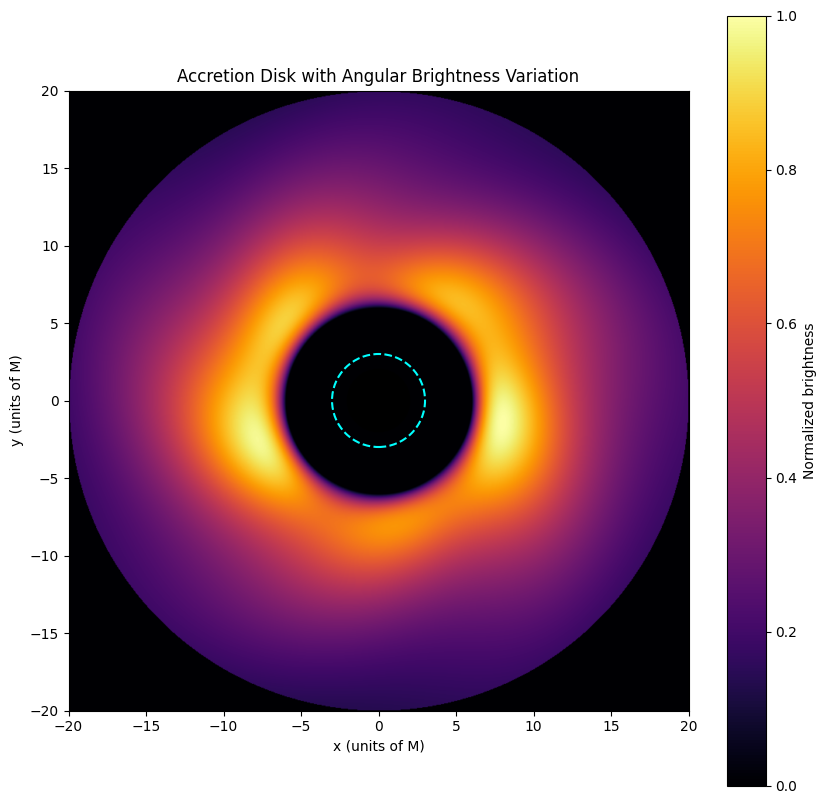

In [ ]:
# # Calculate the angle of each point around the black hole
# phi = np.arctan2(Y, X)

# # Create a subtle angular brightness variation
# angular_pattern = (
#     1
#     + 0.15 * np.cos(2 * phi)
#     + 0.08 * np.sin(5 * phi + R / 3)
# )

# # Apply the pattern and normalize again
# textured_brightness = brightness * angular_pattern
# textured_brightness = (
#     textured_brightness / textured_brightness.max()
# )

# fig, ax = plt.subplots(figsize=(10, 10))

# image = ax.imshow(
#     textured_brightness,
#     extent=[-r_outer, r_outer, -r_outer, r_outer],
#     origin="lower",
#     cmap="inferno",
#     interpolation="bilinear"
# )

# ax.add_patch(Circle((0, 0), r_s, color="black"))
# ax.add_patch(
#     Circle(
#         (0, 0),
#         r_ph,
#         fill=False,
#         linestyle="--",
#         edgecolor="cyan",
#         linewidth=1.5
#     )
# )

# ax.set_aspect("equal")
# ax.set_xlabel("x (units of M)")
# ax.set_ylabel("y (units of M)")
# ax.set_title("Accretion Disk with Angular Brightness Variation")

# plt.colorbar(image, ax=ax, label="Normalized brightness")
# plt.show()